# Module 5 — Campaign incrementality

The campaign assignment was observational, not randomized. We compare four designs, use fake-start placebo checks to look for bias, and collect inputs for the later ROI model. Dollar estimates are per household per week.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
OUT = ROOT / "exports" / "campaigns"
def load(name):
    return pd.read_csv(OUT / f"{name}.csv")
overview = load("campaign_overview")
display(overview[["campaign_id", "campaign_type", "start_date", "end_date", "households", "redemptions"]].sort_values("start_date"))

,campaign_id,campaign_type,start_date,end_date,households,redemptions
0,24,Type C,2016-11-14,2017-01-16,12,0
1,25,Type B,2016-12-06,2017-02-05,17,1
2,26,Type B,2016-12-28,2017-02-19,118,22
3,27,Type A,2017-02-08,2017-03-26,361,64
4,1,Type B,2017-03-03,2017-04-09,13,1
5,2,Type B,2017-03-08,2017-04-09,48,5
6,3,Type C,2017-03-13,2017-05-08,12,2
7,4,Type B,2017-03-29,2017-04-30,81,11
8,5,Type B,2017-04-03,2017-05-07,166,13
9,6,Type C,2017-04-19,2017-05-21,65,1


## 1. Which campaigns can we compare?

I focus on the large Type A campaigns 8, 13 and 18. Campaign 27 begins too early for the required eight-week pre-period. Campaign assignment used past purchases, so targeted households started out different from everyone else.

In [2]:
roi = load("campaign_roi_inputs")
display(roi[["campaign_id", "start_week", "end_week", "weeks", "households", "redemptions", "redeeming_households"]])
print("Grocery households x 52 weeks:", 2_467 * 52)

,campaign_id,start_week,end_week,weeks,households,redemptions,redeeming_households
0,27,7,13,7,361,64,36
1,8,20,26,7,1076,372,158
2,13,33,39,7,1077,629,196
3,18,45,52,8,1133,653,214


Grocery households x 52 weeks: 128284


## 2. Follow the estimate as the design improves

The naive gap compares spending during the campaign. Difference-in-differences (DiD) subtracts each group's earlier spending. Matching also balances the groups on prior spending and activity. The earlier-window method matches on weeks separate from the eight-week before-period to reduce regression-to-the-mean bias.

In [3]:
est = load("guide_compatibility_estimates")
est = est[est.campaign_id.astype(str).isin(["8", "13", "18"])].copy()
est["interval"] = est.apply(lambda r: f"({r.ci_low:+.2f}, {r.ci_high:+.2f})", axis=1)
display(est.pivot(index="campaign_id", columns="method", values="estimate").round(2))
display(est[["campaign_id", "method", "n_treated", "n_control", "estimate", "ci_low", "ci_high"]].round(2))

method,matched_earlier,matched_pre,naive,unmatched
campaign_id,,,,
8,0.80,3.10,32.10,-2.24
13,0.39,6.63,34.31,-0.20
18,2.95,6.27,34.77,1.68


,campaign_id,method,n_treated,n_control,estimate,ci_low,ci_high
0,8,naive,1076,1386,32.10,29.24,34.96
1,8,unmatched,1076,1386,-2.24,-4.10,-0.38
2,8,matched_pre,1076,1386,3.10,-0.06,6.26
3,8,matched_earlier,1073,1252,0.80,-2.71,4.31
4,13,naive,1073,1384,34.31,31.49,37.13
5,13,unmatched,1073,1384,-0.20,-2.00,1.59
6,13,matched_pre,1073,1384,6.63,3.28,9.99
7,13,matched_earlier,1076,1376,0.39,-3.25,4.04
8,18,naive,1133,1327,34.77,31.81,37.73
9,18,unmatched,1133,1327,1.68,-0.01,3.38


The naive +$32–$35 weekly gap is not incremental lift: it largely reflects who was selected. Pre-period matching creates a larger estimate, but a campaign fake-start can create a similar apparent lift before the real campaign. Earlier-window matching yields smaller estimates whose intervals include zero.

In [4]:
placebo = load("placebo_tests")
placebo = placebo[placebo.campaign_id.astype(str).isin(["8", "13", "18"])]
display(placebo[["campaign_id", "method", "status", "estimate", "ci_low", "ci_high", "p_holm"]].round(3))

,campaign_id,method,status,estimate,ci_low,ci_high,p_holm
0,8,matched_pre,estimated,5.682,2.127,9.237,0.009
1,8,matched_earlier,not_estimable_insufficient_history,NaN,NaN,NaN,NaN
2,13,matched_pre,estimated,3.672,-0.789,8.132,0.320
3,13,matched_earlier,estimated,-3.497,-8.749,1.755,0.384
4,18,matched_pre,estimated,4.847,0.731,8.962,0.084
5,18,matched_earlier,estimated,-1.510,-5.705,2.686,0.481


Campaign 8's earlier-window placebo is not estimable because its fake-start would require weeks before the dataset begins. Campaigns 13 and 18 have earlier-window placebo intervals that include zero. A passing placebo does not prove the real estimate is causal; it only removes one warning.

In [5]:
display(load("campaign_overlap_audit"))
display(load("campaign_sensitivities")[["campaign_id", "method", "n_treated", "n_control", "estimate", "ci_low", "ci_high"]].round(2))
display(load("pretrend_tests")[["campaign_id", "contrast", "estimate", "ci_low", "ci_high", "p_holm"]].round(3))
display(load("campaign_window_audit"))

,campaign_id,audit_start,audit_end,other_campaigns,eligible_treated,treated_receiving_other_campaign,eligible_controls,controls_receiving_other_campaign
0,8,2017-03-13,2017-06-25,9,1076,591,1391,168
1,13,2017-06-12,2017-09-24,7,1077,948,1390,249
2,18,2017-09-04,2017-12-24,9,1133,968,1334,250


,campaign_id,method,n_treated,n_control,estimate,ci_low,ci_high
0,8,earlier_tie_preserving_quantiles,1074,1381,1.68,-2.59,5.96
1,8,earlier_excluding_other_campaign_recipients,484,1049,-0.46,-3.99,3.07
2,13,earlier_tie_preserving_quantiles,1077,1378,0.60,-2.97,4.16
3,13,earlier_excluding_other_campaign_recipients,129,781,3.46,-0.68,7.60
4,18,earlier_tie_preserving_quantiles,1124,1326,3.16,-0.33,6.65
5,18,earlier_excluding_other_campaign_recipients,165,762,-0.71,-4.25,2.83


,campaign_id,contrast,estimate,ci_low,ci_high,p_holm
0,8,last_4_pre_weeks_minus_first_4,-2.195,-6.970,2.579,0.735
1,13,last_4_pre_weeks_minus_first_4,3.940,-2.266,10.146,0.640
2,18,last_4_pre_weeks_minus_first_4,1.322,-3.409,6.053,0.735


,campaign_id,start_date,end_date,start_week,end_week,weekly_start_date,weekly_end_date,campaign_calendar_days,modeled_calendar_days,extra_days_before_start,extra_days_after_end,off_date_grocery_sales_all_households
0,27,2017-02-08,2017-03-26,7,13,2017-02-06,2017-03-26,47,49,2,0,21289.89
1,8,2017-05-08,2017-06-25,20,26,2017-05-08,2017-06-25,49,49,0,0,0.00
2,13,2017-08-08,2017-09-24,33,39,2017-08-07,2017-09-24,48,49,1,0,12537.03
3,18,2017-10-30,2017-12-24,45,52,2017-10-30,2017-12-24,56,56,0,0,0.00


## 3. Inspect the weekly pattern and the money inputs

The weekly chart shows the noisy gap for Campaign 18. Pointwise intervals are separate from the pre-period contrasts above and do not validate parallel trends. Campaigns overlap, and the source has no print or distribution cost data. Whole source weeks approximate campaign dates: Campaign 13 includes one day before its actual Tuesday start.

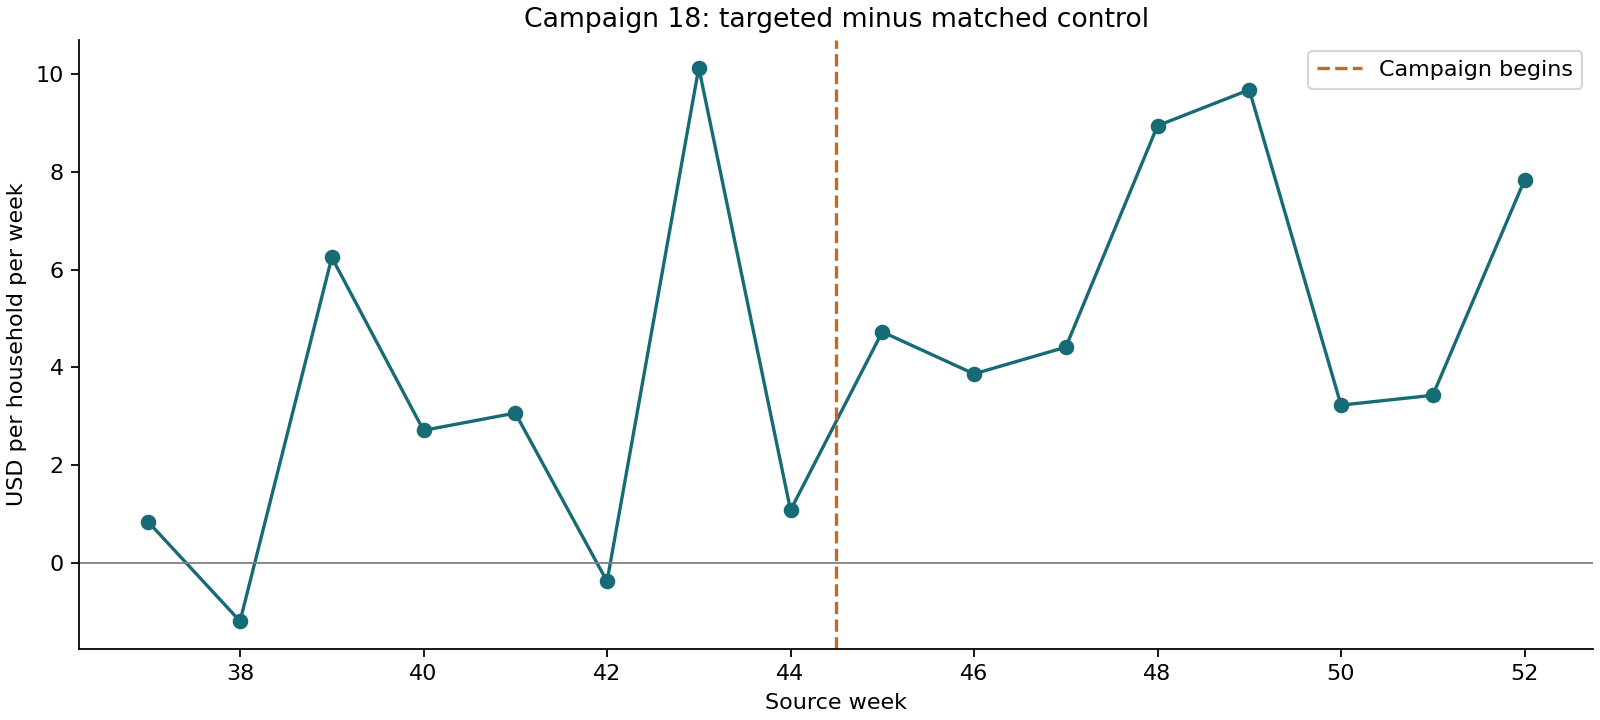

,campaign_id,campaign_type,start_date,end_date,start_week,end_week,weeks,households,redemptions,redeeming_households,matched_supported_treated,matched_supported_controls,estimate,ci_low,ci_high,estimated_change_supported_sample,ci_low_supported_sample,ci_high_supported_sample,costs_observed,extrapolation_to_all_recipients_validated
0,27,Type A,2017-02-08,2017-03-26,7,13,7,361,64,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
1,8,Type A,2017-05-08,2017-06-25,20,26,7,1076,372,158,1073.0,1252.0,0.803055,-2.705339,4.311448,6031.742530,-20319.804480,32383.289540,False,False
2,13,Type A,2017-08-08,2017-09-24,33,39,7,1077,629,196,1076.0,1376.0,0.394533,-3.250684,4.039750,2971.621836,-24484.155399,30427.399071,False,False
3,18,Type A,2017-10-30,2017-12-24,45,52,8,1133,653,214,1131.0,1331.0,2.950239,-0.736966,6.637444,26693.765591,-6668.063850,60055.595032,False,False


,positive_coupon_lines,average_manufacturer_coupon_line_amount,median_manufacturer_coupon_line_amount
0,18911,1.047835,0.75


In [6]:
display(Image(filename=str(ROOT / "charts" / "campaign18_pretrend.png")))
display(load("campaign_roi_inputs"))
display(load("coupon_amount_summary"))

## 4. Run the workflow yourself in SQL

Open `grocery_campaigns.duckdb` in any SQL client, then run one statement at a time from `sql/05_campaigns_learning.sql` with Ctrl+Enter. These are small reporting tables. The full household-week model and statistical estimates are reproducible with `scripts/run_campaigns.py`.

**Conclusion:** the best observational design finds a small, uncertain spend change. Recommend a randomized household holdout and measure net revenue and retailer costs before claiming campaign ROI.

In [7]:
checks = load("campaign_checks")
assert checks["passed"].astype(str).str.lower().eq("true").all()
print(f"{len(checks)} campaign checks passed")
display(checks)

25 campaign checks passed


,check_name,passed
0,52_week_rows_per_household,True
1,campaign_keys_unique,True
2,household_week_grain_unique,True
3,household_week_size,True
4,recipient_counts_reconcile,True
5,redemptions_reconcile,True
6,selected_campaign_windows_present,True
7,selected_window_dates_mapped,True
8,source_week_local_dates_consistent,True
9,spend_nonnegative,True
